In [1]:
import pandas as pd
import matplotlib.pyplot as plt

# Load the generated synthetic data
csv_path = "../backend/data_generation/generated_logs.csv"
df = pd.read_csv(csv_path)

# Display the first few rows to verify it loaded correctly
display(df.head())

,student_id,profile,step,concept,passed,time_taken
0,STU_0001,Struggling Learner,1,Syntax,0,134
1,STU_0001,Struggling Learner,2,Primitive Data Types,1,107
2,STU_0001,Struggling Learner,3,Variables,0,61
3,STU_0001,Struggling Learner,4,Lists,0,103
4,STU_0001,Struggling Learner,5,Arithmetic Operators,0,97


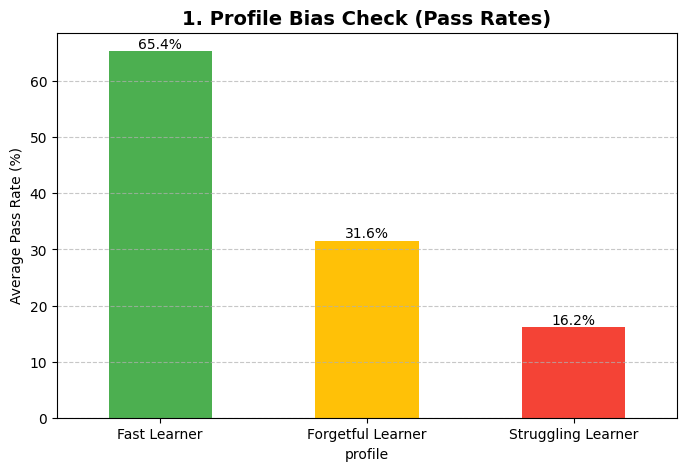

In [2]:
# 1. Distributional Parity (Profile Pass Rates)
plt.figure(figsize=(8, 5))
profile_stats = df.groupby('profile')['passed'].mean() * 100

# Create the bar chart
bars = profile_stats.plot(kind='bar', color=['#4CAF50', '#FFC107', '#F44336'])

plt.title('1. Profile Bias Check (Pass Rates)', fontsize=14, fontweight='bold')
plt.ylabel('Average Pass Rate (%)')
plt.xticks(rotation=0)
plt.grid(axis='y', linestyle='--', alpha=0.7)

# Add percentage labels on top of the bars
for p in bars.patches:
    bars.annotate(f'{p.get_height():.1f}%', 
                  (p.get_x() + p.get_width() / 2., p.get_height()), 
                  ha='center', va='bottom', fontsize=10)

plt.show()

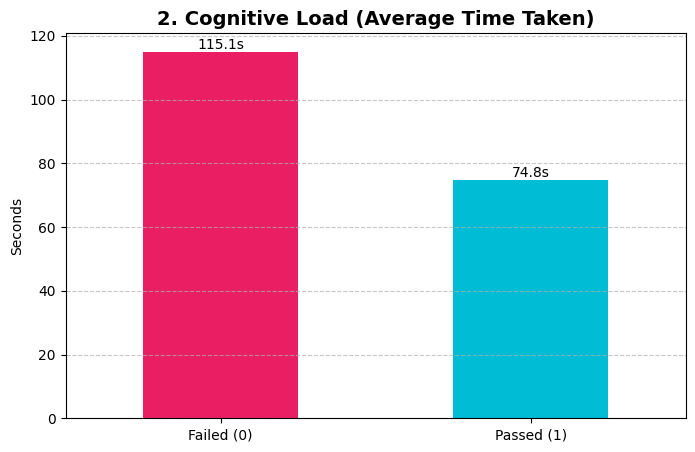

In [3]:
# 2. Cognitive Load Correlation (Time vs. Mastery)
plt.figure(figsize=(8, 5))
time_stats = df.groupby('passed')['time_taken'].mean()
time_stats.index = ['Failed (0)', 'Passed (1)']

bars = time_stats.plot(kind='bar', color=['#E91E63', '#00BCD4'])

plt.title('2. Cognitive Load (Average Time Taken)', fontsize=14, fontweight='bold')
plt.ylabel('Seconds')
plt.xticks(rotation=0)
plt.grid(axis='y', linestyle='--', alpha=0.7)

for p in bars.patches:
    bars.annotate(f'{p.get_height():.1f}s', 
                  (p.get_x() + p.get_width() / 2., p.get_height()), 
                  ha='center', va='bottom', fontsize=10)

plt.show()

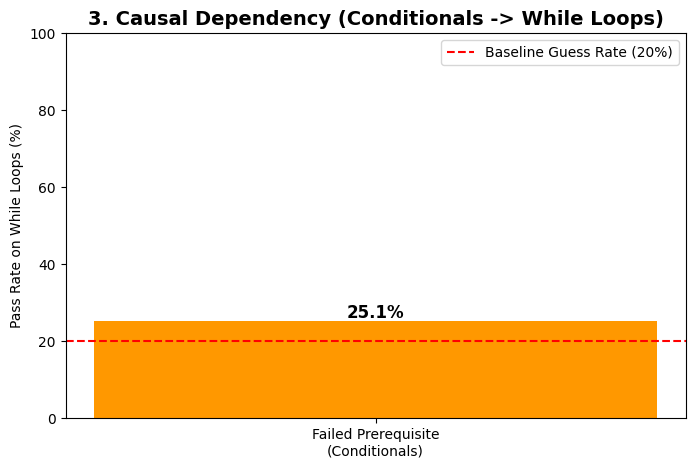

In [4]:
# 3. Causal Dependency Violation Rate
plt.figure(figsize=(8, 5))

# Find students who failed Conditionals, then check their pass rate on While Loops
failed_cond = df[(df['concept'] == 'Conditionals') & (df['passed'] == 0)]['student_id']
dep_attempts = df[(df['student_id'].isin(failed_cond)) & (df['concept'] == 'While Loops')]
violation_rate = dep_attempts['passed'].mean() * 100

plt.bar(['Failed Prerequisite\n(Conditionals)'], [violation_rate], color='#FF9800', width=0.4)
plt.title('3. Causal Dependency (Conditionals -> While Loops)', fontsize=14, fontweight='bold')
plt.ylabel('Pass Rate on While Loops (%)')
plt.ylim(0, 100)

# Add the baseline guess rate line
plt.axhline(y=20, color='r', linestyle='--', label='Baseline Guess Rate (20%)')
plt.legend()

plt.annotate(f'{violation_rate:.1f}%', xy=(0, violation_rate), ha='center', va='bottom', fontsize=12, fontweight='bold')

plt.show()

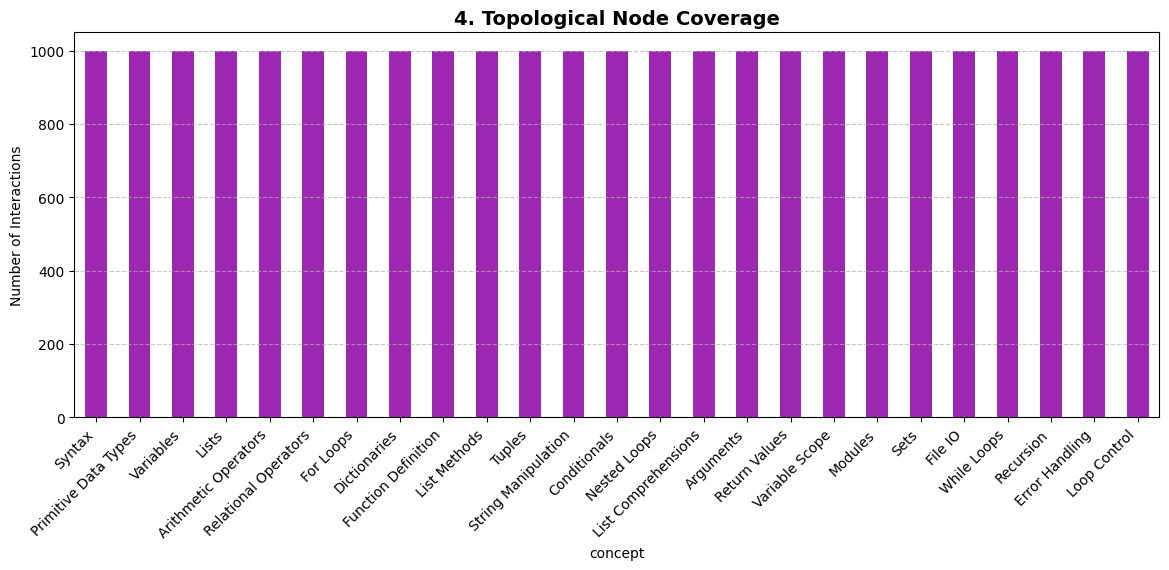

In [5]:
# 4. Topological Node Coverage
plt.figure(figsize=(14, 5))
node_counts = df['concept'].value_counts()

node_counts.plot(kind='bar', color='#9C27B0')

plt.title('4. Topological Node Coverage', fontsize=14, fontweight='bold')
plt.ylabel('Number of Interactions')
plt.xticks(rotation=45, ha='right') # Angled text so the 25 nodes fit nicely
plt.grid(axis='y', linestyle='--', alpha=0.7)

plt.show()

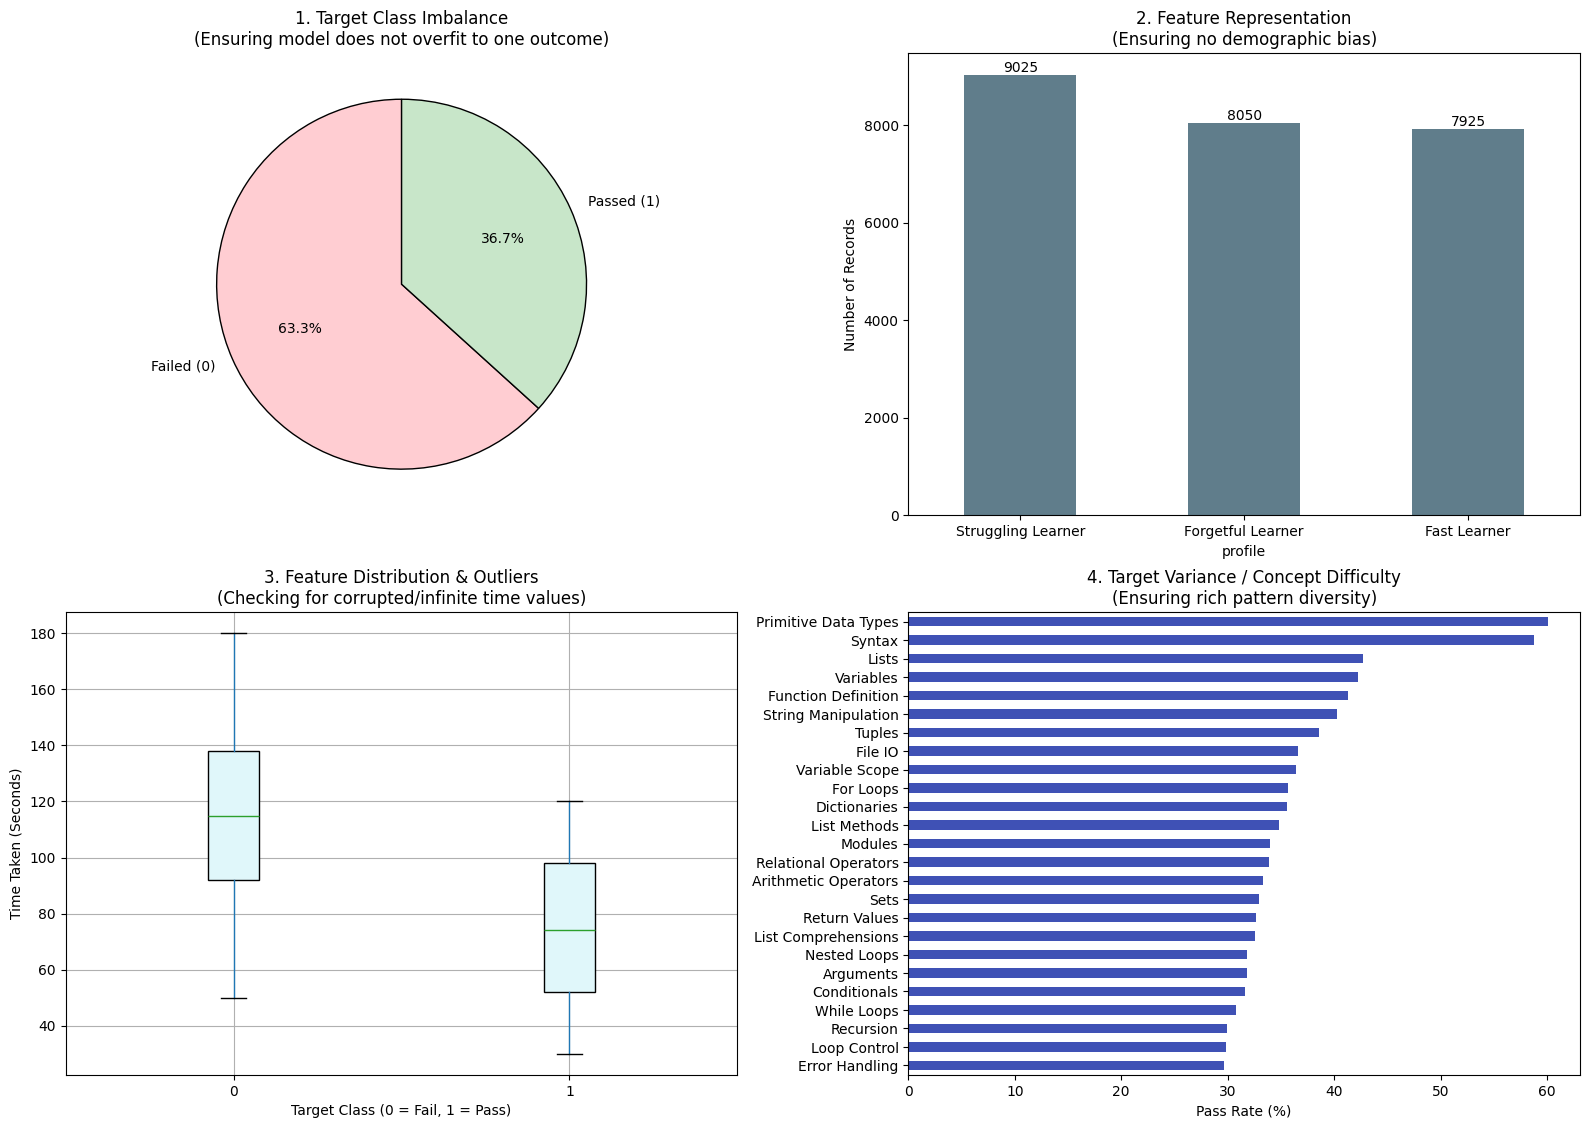

In [6]:
# 5. Conventional Machine Learning Integrity Metrics
plt.figure(figsize=(16, 12))
plt.suptitle('Conventional ML Dataset Health Checks', fontsize=18, fontweight='bold')

# --- 1. Target Class Imbalance ---
plt.subplot(2, 2, 1)
pass_counts = df['passed'].value_counts().rename({0: 'Failed (0)', 1: 'Passed (1)'})
pass_counts.plot(kind='pie', autopct='%1.1f%%', colors=['#FFCDD2', '#C8E6C9'], 
                 startangle=90, wedgeprops={'edgecolor': 'black'})
plt.title('1. Target Class Imbalance\n(Ensuring model does not overfit to one outcome)')
plt.ylabel('')

# --- 2. Feature Representation (Profile Balance) ---
plt.subplot(2, 2, 2)
profile_counts = df['profile'].value_counts()
bars = profile_counts.plot(kind='bar', color='#607D8B')
plt.title('2. Feature Representation\n(Ensuring no demographic bias)')
plt.ylabel('Number of Records')
plt.xticks(rotation=0)
for p in bars.patches:
    bars.annotate(f'{int(p.get_height())}', 
                  (p.get_x() + p.get_width() / 2., p.get_height()), 
                  ha='center', va='bottom', fontsize=10)

# --- 3. Feature Distribution & Outliers (Box Plot) ---
plt.subplot(2, 2, 3)
bp = df.boxplot(column='time_taken', by='passed', ax=plt.gca(), 
                patch_artist=True, boxprops=dict(facecolor='#E0F7FA'))
plt.title('3. Feature Distribution & Outliers\n(Checking for corrupted/infinite time values)')
plt.suptitle('') # Removes pandas default title
plt.xlabel('Target Class (0 = Fail, 1 = Pass)')
plt.ylabel('Time Taken (Seconds)')

# --- 4. Target Variance (Difficulty Gradient) ---
plt.subplot(2, 2, 4)
# Calculate pass rate per concept and sort them to show the gradient
concept_pass_rates = df.groupby('concept')['passed'].mean().sort_values() * 100
concept_pass_rates.plot(kind='barh', color='#3F51B5')
plt.title('4. Target Variance / Concept Difficulty\n(Ensuring rich pattern diversity)')
plt.xlabel('Pass Rate (%)')
plt.ylabel('')

plt.tight_layout()
plt.subplots_adjust(top=0.90) # Adjust to fit the main title
plt.show()